# Telco Customer Churn - 05. High-Risk Profiling & Recommendations
Steps 16-18: explain important features, high-risk customer profiling, business recommendations.

## 0. Setup (recap)
Reloads the data and re-derives earlier decisions, so this notebook can run on its own.

In [1]:
import os, hashlib, warnings, platform, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from scipy.stats import loguniform, randint

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 160)

In [2]:
from google.colab import files

uploaded = files.upload()
EXPECTED_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert EXPECTED_FILE in uploaded, f"Please upload {EXPECTED_FILE}"

DATA_PATH = Path(EXPECTED_FILE)
sha = hashlib.sha256(open(DATA_PATH, "rb").read()).hexdigest()
raw = pd.read_csv(DATA_PATH)

ADDONS = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
df0 = raw.copy()
df0["TotalCharges"] = pd.to_numeric(df0.TotalCharges.astype(str).str.strip().replace("", np.nan), errors="coerce").fillna(0.0)
df0["ChurnFlag"] = (df0.Churn == "Yes").astype(int)

y = df0["ChurnFlag"]
X = df0.drop(columns=["customerID", "Churn", "ChurnFlag"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Recap loaded. Train:", X_train.shape, "Test:", X_test.shape, "| SHA-256:", sha)

Recap loaded. Train: (5634, 19) Test: (1409, 19) | SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [3]:
SIMPLIFY = ["MultipleLines"] + ADDONS
NUM_BASE = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
CAT_BASE = ["gender","Partner","Dependents","PhoneService","MultipleLines","InternetService"] + ADDONS + \
           ["Contract","PaperlessBilling","PaymentMethod"]

def make_features(X, extras=(), drop_gender=False):
    X = X.copy()
    for c in SIMPLIFY:
        X[c] = X[c].replace({"No internet service": "No", "No phone service": "No"})
    if "n_addons" in extras:
        X["n_addons"] = (X[ADDONS] == "Yes").sum(axis=1)
    if "autopay" in extras:
        X["autopay"] = X["PaymentMethod"].str.contains("automatic").astype(int)
    if "charge_gap" in extras:
        t = X["tenure"].where(X["tenure"] > 0)
        X["charge_gap"] = (X["MonthlyCharges"] - X["TotalCharges"] / t).fillna(0.0)
    if drop_gender:
        X = X.drop(columns=["gender"])
    return X

def build_pipeline(clf, extras=(), drop_gender=False, scale=True):
    num = NUM_BASE + [e for e in ("n_addons", "charge_gap", "autopay") if e in extras]
    cat = [c for c in CAT_BASE if not (drop_gender and c == "gender")]
    prep = ColumnTransformer(
        [("num", StandardScaler() if scale else "passthrough", num),
         ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat)],
        remainder="drop", verbose_feature_names_out=False)
    steps = [("fe", FunctionTransformer(make_features, kw_args={"extras": tuple(extras), "drop_gender": drop_gender})),
             ("prep", prep), ("clf", clf)]
    return Pipeline(steps)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
INNER = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}
def run_cv(model, X, y, scoring=SCORING):
    res = cross_validate(model, X, y, cv=CV, scoring=scoring, n_jobs=-1)
    return {k[5:]: v for k, v in res.items() if k.startswith("test_")}
def ms(v): return f"{np.mean(v):.3f} \u00b1 {np.std(v):.3f}"
print("Pipeline helper functions ready.")

Pipeline helper functions ready.


In [4]:
# Recap of the feature/imbalance decisions made in 02_Preprocessing.ipynb (re-derived here so this notebook stands alone)
configs = {"base": ((), False), "+n_addons": (("n_addons",), False), "+autopay": (("autopay",), False),
           "+charge_gap": (("charge_gap",), False), "drop gender": ((), True)}
two = {"LogReg": (lambda: LogisticRegression(max_iter=2000), True),
       "HistGB": (lambda: HistGradientBoostingClassifier(random_state=SEED, max_iter=150, learning_rate=0.05), False)}
abl = {}
for cname, (ex, dg) in configs.items():
    for mname, (mk, sc) in two.items():
        abl[(cname, mname)] = run_cv(build_pipeline(mk(), ex, dg, sc), X_train, y_train, {"pr_auc": "average_precision"})
EXTRAS = tuple(e for e, k in [("n_addons", "+n_addons"), ("autopay", "+autopay"), ("charge_gap", "+charge_gap")]
               if all(abl[(k, m)]["pr_auc"].mean() > abl[("base", m)]["pr_auc"].mean() for m in two))
DROP_GENDER = all(abl[("drop gender", m)]["pr_auc"].mean() >= abl[("base", m)]["pr_auc"].mean() - 0.001 for m in two)

variants = {"none": build_pipeline(LogisticRegression(max_iter=2000), EXTRAS, DROP_GENDER, True),
            "balanced": build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), EXTRAS, DROP_GENDER, True)}
imb = {n: run_cv(m, X_train, y_train) for n, m in variants.items()}
USE_WEIGHTS = imb["balanced"]["pr_auc"].mean() > imb["none"]["pr_auc"].mean() + imb["none"]["pr_auc"].std()
CLASS_WEIGHT = "balanced" if USE_WEIGHTS else None

def all_models():
    cw = CLASS_WEIGHT
    return {
     "Dummy":        build_pipeline(DummyClassifier(strategy="prior"), EXTRAS, DROP_GENDER, False),
     "LogReg":       build_pipeline(LogisticRegression(max_iter=2000, class_weight=cw), EXTRAS, DROP_GENDER, True),
     "DecisionTree": build_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
     "RandomForest": build_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw, random_state=SEED, n_jobs=-1), EXTRAS, DROP_GENDER, False),
     "HistGB":       build_pipeline(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
    }
print("Kept features:", EXTRAS, "| Drop gender:", DROP_GENDER, "| Class weight:", CLASS_WEIGHT)

Kept features: ('n_addons',) | Drop gender: True | Class weight: None


In [5]:
# Recap of model tuning from 03_Model_Training.ipynb (re-derived here so this notebook stands alone)
SPACES = {
 "LogReg":       {"clf__C": loguniform(1e-3, 1e2)},
 "DecisionTree": {"clf__max_depth": randint(2, 12), "clf__min_samples_leaf": randint(5, 100), "clf__criterion": ["gini", "entropy"]},
 "RandomForest": {"clf__n_estimators": randint(150, 400), "clf__max_depth": randint(4, 16), "clf__min_samples_leaf": randint(2, 30),
                  "clf__max_features": ["sqrt", 0.3, 0.5]},
 "HistGB":       {"clf__learning_rate": loguniform(0.02, 0.2), "clf__max_iter": randint(80, 300), "clf__max_leaf_nodes": randint(6, 32),
                  "clf__min_samples_leaf": randint(10, 80), "clf__l2_regularization": loguniform(1e-3, 10)},
}
N_ITER = {"LogReg": 10, "DecisionTree": 15, "RandomForest": 12, "HistGB": 12}
TUNE = list(SPACES)

def make_search(name, cv=INNER):
    return RandomizedSearchCV(all_models()[name], SPACES[name], n_iter=N_ITER[name], scoring="average_precision",
                              cv=cv, random_state=SEED, n_jobs=-1, refit=True)

nested = {}
for name in TUNE:
    res = cross_validate(make_search(name), X_train, y_train, cv=CV, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=1)
    nested[name] = {"roc_auc": res["test_roc_auc"], "pr_auc": res["test_pr_auc"]}

order = ["LogReg", "DecisionTree", "RandomForest", "HistGB"]
best_name = max(TUNE, key=lambda n: nested[n]["pr_auc"].mean())
se_best = nested[best_name]["pr_auc"].std() / np.sqrt(len(nested[best_name]["pr_auc"]))
eligible = [n for n in order if nested[n]["pr_auc"].mean() >= nested[best_name]["pr_auc"].mean() - se_best]
FINAL_NAME = eligible[0]

final_search = make_search(FINAL_NAME, cv=CV)
final_search.fit(X_train, y_train)
final_model = final_search.best_estimator_
print("Final model:", FINAL_NAME, "| Best params:", final_search.best_params_)

Final model: LogReg | Best params: {'clf__C': np.float64(4.5705630998014515)}


In [6]:
# Recap of threshold selection from 04_Model_Evaluation.ipynb (re-derived here so this notebook stands alone)
OFFER_COST, SAVE_RATE, VALUE_MONTHS = 20.0, 0.30, 12

def net_benefit_per_1000(y_true, flagged, monthly, save_rate=SAVE_RATE, offer_cost=OFFER_COST):
    y_true, flagged, monthly = np.asarray(y_true), np.asarray(flagged).astype(bool), np.asarray(monthly)
    gain = (y_true[flagged] * save_rate * VALUE_MONTHS * monthly[flagged]).sum() - offer_cost * flagged.sum()
    return 1000 * gain / len(y_true)

oof = cross_val_predict(clone(final_model), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.round(np.arange(0.02, 0.91, 0.01), 2)
mc_train = X_train["MonthlyCharges"].values
benefits = [net_benefit_per_1000(y_train, oof >= t, mc_train) for t in grid]
THRESHOLD = float(grid[int(np.argmax(benefits))])

p_test = final_model.predict_proba(X_test)[:, 1]
pred = (p_test >= THRESHOLD).astype(int)
yt = y_test.values
print("Final model:", FINAL_NAME, "| Threshold:", THRESHOLD, "| Test ROC-AUC:", round(roc_auc_score(yt, p_test), 3))

Final model: LogReg | Threshold: 0.07 | Test ROC-AUC: 0.842


## 16. Explain Important Features
Permutation importance, coefficients (if linear), and a readable surrogate tree.

In [7]:
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("importance", ascending=False).reset_index(drop=True)
display(imp.head(12).round(4))

,feature,importance,std
0,tenure,0.1757,0.0051
1,InternetService,0.1707,0.0143
2,MonthlyCharges,0.0785,0.0088
3,Contract,0.0346,0.0040
4,TotalCharges,0.0161,0.0025
5,StreamingMovies,0.0078,0.0024
6,StreamingTV,0.0074,0.0031
7,MultipleLines,0.0043,0.0018
8,PaymentMethod,0.0032,0.0016
9,PaperlessBilling,0.0028,0.0016


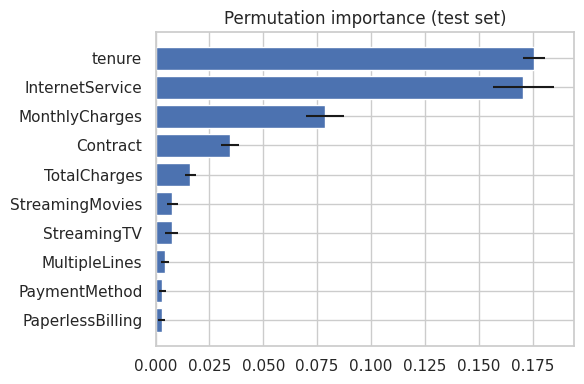

In [8]:
top = imp.head(10).iloc[::-1]
plt.figure(figsize=(6,4)); plt.barh(top.feature, top.importance, xerr=top["std"], color="#4C72B0")
plt.title("Permutation importance (test set)"); plt.tight_layout(); plt.show()

In [9]:
clf = final_model.named_steps["clf"]
names = final_model.named_steps["prep"].get_feature_names_out()
if hasattr(clf, "coef_"):
    coefs = pd.Series(clf.coef_[0], index=names).sort_values()
    display(pd.concat([coefs.head(6), coefs.tail(6)]).round(3).to_frame("coefficient"))

,coefficient
InternetService_No,-2.205
tenure,-1.291
MonthlyCharges,-1.215
Contract_Two year,-1.077
OnlineSecurity_Yes,-0.595
TechSupport_Yes,-0.543
Contract_Month-to-month,0.292
PaperlessBilling_Yes,0.370
MultipleLines_Yes,0.484
TotalCharges,0.571


In [10]:
Z_train = final_model.named_steps["prep"].transform(final_model.named_steps["fe"].transform(X_train))
sur = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED).fit(Z_train, (oof >= THRESHOLD).astype(int))
print(export_text(sur, feature_names=list(names)))

|--- Contract_Month-to-month <= 0.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- Contract_Two year <= 0.50
|   |   |   |--- class: 0
|   |   |--- Contract_Two year >  0.50
|   |   |   |--- class: 0
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- Contract_Two year <= 0.50
|   |   |   |--- class: 1
|   |   |--- Contract_Two year >  0.50
|   |   |   |--- class: 0
|--- Contract_Month-to-month >  0.50
|   |--- tenure <= -0.33
|   |   |--- tenure <= -0.49
|   |   |   |--- class: 1
|   |   |--- tenure >  -0.49
|   |   |   |--- class: 1
|   |--- tenure >  -0.33
|   |   |--- MonthlyCharges <= -1.17
|   |   |   |--- class: 0
|   |   |--- MonthlyCharges >  -1.17
|   |   |   |--- class: 1



## 17. High-Risk Customer Profiling
Describe the flagged group vs the rest (test set).

In [11]:
flag = pd.Series(pred == 1, index=X_test.index)
prof = pd.DataFrame({
 "flagged": {"share of customers": flag.mean(), "actual churn rate": y_test[flag].mean(),
             "median tenure": X_test.tenure[flag].median(), "median MonthlyCharges": X_test.MonthlyCharges[flag].median(),
             "% month-to-month": (X_test.Contract[flag]=="Month-to-month").mean(),
             "% fibre optic": (X_test.InternetService[flag]=="Fiber optic").mean(),
             "% electronic check": (X_test.PaymentMethod[flag]=="Electronic check").mean()},
 "not flagged": {"share of customers": 1-flag.mean(), "actual churn rate": y_test[~flag].mean(),
             "median tenure": X_test.tenure[~flag].median(), "median MonthlyCharges": X_test.MonthlyCharges[~flag].median(),
             "% month-to-month": (X_test.Contract[~flag]=="Month-to-month").mean(),
             "% fibre optic": (X_test.InternetService[~flag]=="Fiber optic").mean(),
             "% electronic check": (X_test.PaymentMethod[~flag]=="Electronic check").mean()}})
display(prof.round(3))

,flagged,not flagged
share of customers,0.681,0.319
actual churn rate,0.379,0.022
median tenure,16.000,57.000
median MonthlyCharges,75.300,45.250
% month-to-month,0.781,0.051
% fibre optic,0.585,0.114
% electronic check,0.467,0.058


## 18. Business Recommendations
Compare campaign policies and their expected net benefit under the stated assumptions.

In [12]:
mc_test = X_test["MonthlyCharges"].values
rank = np.argsort(-p_test)
rows = []
for k in [0.10, 0.20, 0.30, 0.40]:
    m = int(round(k * len(yt))); flagged = np.zeros(len(yt), bool); flagged[rank[:m]] = True
    rows.append({"policy": f"top {int(k*100)}%", "contacted": m, "churners reached": int(yt[flagged].sum()),
                 "precision": yt[flagged].mean(), "net benefit / 1000": net_benefit_per_1000(yt, flagged, mc_test)})
rows.append({"policy": f"score >= {THRESHOLD:.2f}", "contacted": int(flag.sum()), "churners reached": int(yt[flag].sum()),
             "precision": yt[flag].mean(), "net benefit / 1000": net_benefit_per_1000(yt, flag.values, mc_test)})
rows.append({"policy": "contact everyone", "contacted": len(yt), "churners reached": int(yt.sum()),
             "precision": yt.mean(), "net benefit / 1000": net_benefit_per_1000(yt, np.ones(len(yt), bool), mc_test)})
policy = pd.DataFrame(rows)
display(policy.round(2))

,policy,contacted,churners reached,precision,net benefit / 1000
0,top 10%,141,104,0.74,19512.22
1,top 20%,282,187,0.66,33758.58
2,top 30%,423,244,0.58,42490.86
3,top 40%,564,291,0.52,49009.48
4,score >= 0.07,960,364,0.38,54060.09
5,contact everyone,1409,374,0.27,49534.17
